# Task 5: Model Iterations

In this task, your group will focus on training and evaluating multiple machine learning models to classify emotions in transcribed television show data. This exercise will help you understand how different models perform on the same dataset and will provide insights into model selection and optimization. For every type of model and/or iteration that you do, track the details in the model iteration file that you will find attached to the final assignment on Brightspace. You need to keep one file per group. You will need this information later to complete your model card for the model that is included in your pipeline. In order to improve your models, you are highly encouraged to use (a selection of) traditional NLP features that you extracted in the ‘NLP Features’ task.

**Requirements**
You are required to implement the models listed above and have at minimum three models trained/implemented/iterated on that use in total at minimum three features as extracted in task 4. If this is not visible in your model iteration file including the matching code files linked, you will recieve 0 points for ILO8.9A and 8.9B.

For every model logged in the model iteration file, all cells in the row must be filled. If a row is not completely filled, it does not count towards the final submission.

**ILO mapping**
This task is linked to ILO 8.9A and 8.9B.

**Evidencing**
Link the model iteration file in your learning log. Write a short description of how you meet the criteria.

### Notebook description
This is the third iteration of the Transformer model, BERT. It uses the datasets; final_evaluated_dataset.xlsx, CARER and GoEmotions. I combined the datasets using the notebook: `creating_new_dataset` into one dataset, `combined3.csv`.

**Dataset Composition:**

The `final_evaluated_dataset.xlsx` contains episode transcriptions from three different Dutch television shows: Expeditie Robinson (Survivor), Hunted, and Big Brother. The transcriptions and translations are done with the current Content Intelligence Agency pipeline, which uses the OpenAI API and annotated by students. The result is a dataset of 3856 lines for which the emotions are manually checked.

**The CARER dataset**

The CARER dataset, abbreviated from Contextualized Affect Representations for Emotion Recognition, consists of 416,809 English tweets labeled via distant supervision and not manually annotated. Distant supervision is a labeling method where data is automatically annotated using existing information, like keywords or external databases, instead of manual labeling by humans. It helps quickly create large datasets but may include noisy or inaccurate labels.

Reference:
[CARER: Contextualized Affect Representations for Emotion Recognition](https://aclanthology.org/D18-1404/) (Saravia et al., EMNLP 2018)

**GoEmotions**

GoEmotions is a human-annotated dataset of 58,009 Reddit comments labeled with 27 fine-grained emotion categories plus a neutral label. It is the largest fully labeled English-language emotion dataset, designed for nuanced emotion classification in conversational text. Unlike prior datasets that focus on basic emotions, GoEmotions includes a diverse taxonomy of 12 positive, 11 negative, and 4 ambiguous emotions, making it suitable for applications like empathetic AI and online behavior analysis. The dataset was curated to reduce biases, filter offensive content, and ensure balanced representation across subreddits.

Reference: 
[GoEmotions: A Dataset of Fine-Grained Emotions](https://aclanthology.org/2020.acl-main.372/) (Demszky et al., ACL 2020)

In [1]:
import torch
import pandas as pd
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np
from transformers import BertTokenizer, BertForSequenceClassification
from torch.utils.data import DataLoader, Dataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, f1_score, classification_report

c:\Users\pkomi\anaconda3\envs\bc2\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Load dataset
df = pd.read_csv("../data/raw/combined_3.csv")

# Tokenizer
tokenizer = BertTokenizer.from_pretrained("bert-base-uncased")

In [3]:
# Count occurrences of each emotion
emotion_counts = df['main_emotion'].value_counts()

# Display the counts
print(emotion_counts)

main_emotion
happiness    215729
sadness      131416
anger         71517
fear          49575
neutral       43378
surprise      20707
disgust        1954
Name: count, dtype: int64


As a result from the error analysis, I decided to implement max samples for this iteration to ensure even distribution of all labels. With this, the dataset will be balanced and the result will be more insightful.

In [5]:
# Define features and target
X = df["Translation"].astype(str)
y = df["main_emotion"]

In [6]:
# Encode target labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

In [8]:
# Split into train (70%), validation (15%), and test (15%) sets
X_train, X_temp, y_train, y_temp = train_test_split(X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

In [9]:
# Sample dataset class
class EmotionDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=128):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        encoding = self.tokenizer(
            self.texts[idx],
            truncation=True,
            padding='max_length',
            max_length=self.max_len,
            return_tensors='pt'
        )
        return {
            'input_ids': encoding['input_ids'].squeeze(0),
            'attention_mask': encoding['attention_mask'].squeeze(0),
            'label': torch.tensor(self.labels[idx], dtype=torch.long)
        }

In [10]:
# Create dataset objects
train_dataset = EmotionDataset(X_train.tolist(), y_train.tolist(), tokenizer)
val_dataset = EmotionDataset(X_val.tolist(), y_val.tolist(), tokenizer)
test_dataset = EmotionDataset(X_test.tolist(), y_test.tolist(), tokenizer)

# Create DataLoaders
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

In [11]:
# Load pre-trained BERT model
num_classes = len(label_encoder.classes_)  # Dynamically set based on dataset
model = BertForSequenceClassification.from_pretrained('bert-base-uncased', num_labels=num_classes)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

# Training setup
optimizer = optim.AdamW(model.parameters(), lr=2e-5)
criterion = nn.CrossEntropyLoss()

def train(model, train_loader):
    model.train()
    total_loss, total_correct = 0, 0
    predictions, true_labels = [], []
    for batch in train_loader:
        optimizer.zero_grad()
        input_ids, attention_mask, labels = batch['input_ids'].to(device), batch['attention_mask'].to(device), batch['label'].to(device)
        outputs = model(input_ids, attention_mask=attention_mask)
        loss = criterion(outputs.logits, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
        preds = torch.argmax(outputs.logits, dim=1)
        predictions.extend(preds.cpu().numpy())
        true_labels.extend(labels.cpu().numpy())
    return total_loss / len(train_loader), accuracy_score(true_labels, predictions)

def evaluate(model, train_loader):
    model.eval()
    predictions, true_labels = [], []
    with torch.no_grad():
        for batch in train_loader:
            input_ids, attention_mask, labels = batch['input_ids'].to(device), batch['attention_mask'].to(device), batch['label'].to(device)
            outputs = model(input_ids, attention_mask=attention_mask)
            preds = torch.argmax(outputs.logits, dim=1)
            predictions.extend(preds.cpu().numpy())
            true_labels.extend(labels.cpu().numpy())
    acc = accuracy_score(true_labels, predictions)
    f1 = f1_score(true_labels, predictions, average='weighted')
    return acc, f1, classification_report(true_labels, predictions)

for epoch in range(3):
    train_loss, train_acc = train(model, train_loader)  # Train on train_loader
    val_acc, val_f1, val_report = evaluate(model, val_loader)  # Evaluate on validation set

    print(f"Epoch {epoch+1}: Train Loss = {train_loss:.4f}, Train Acc = {train_acc:.4f}")
    print(f"Validation Acc = {val_acc:.4f}, Validation F1 = {val_f1:.4f}")
    print(val_report)

test_acc, test_f1, test_report = evaluate(model, test_loader)
print(f"Final Test Acc = {test_acc:.4f}, Test F1 = {test_f1:.4f}")
print(test_report)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch 1: Train Loss = 0.3181, Train Acc = 0.8736
Validation Acc = 0.8797, Validation F1 = 0.8819
              precision    recall  f1-score   support

           0       0.85      0.86      0.85      7152
           1       0.39      0.29      0.33       195
           2       0.93      0.83      0.88      4958
           3       0.93      0.94      0.94     21573
           4       0.55      0.66      0.60      4338
           5       0.96      0.91      0.93     13141
           6       0.71      0.72      0.71      2071

    accuracy                           0.88     53428
   macro avg       0.76      0.74      0.75     53428
weighted avg       0.89      0.88      0.88     53428

Epoch 2: Train Loss = 0.2730, Train Acc = 0.8871
Validation Acc = 0.8788, Validation F1 = 0.8792
              precision    recall  f1-score   support

           0       0.85      0.85      0.85      7152
           1       0.36      0.38      0.37       195
           2       0.93      0.80      0.86   

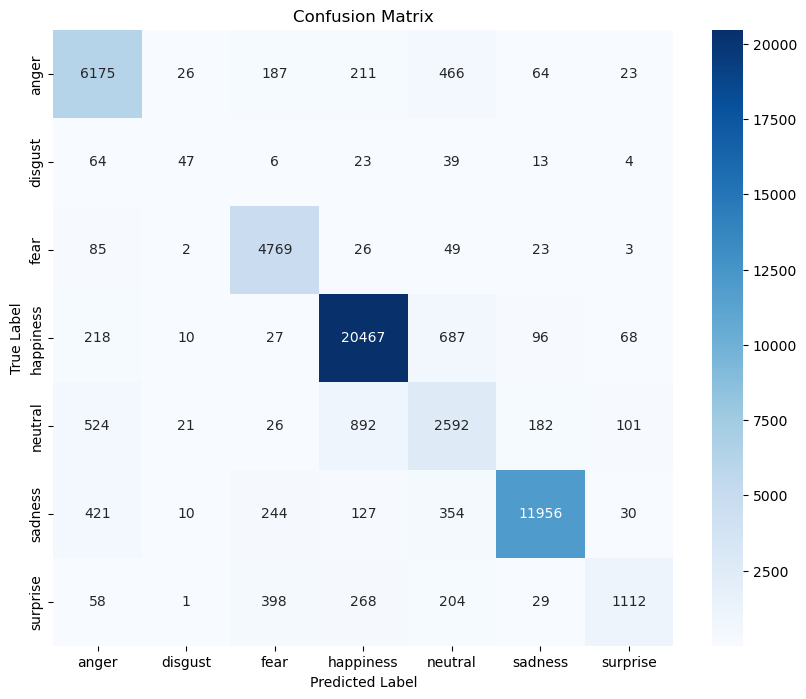

In [12]:
# Get predictions on test set
y_true = []
y_pred = []

model.eval()
with torch.no_grad():
    for batch in test_loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['label'].to(device)
        
        outputs = model(input_ids, attention_mask=attention_mask)
        preds = torch.argmax(outputs.logits, dim=1)
        
        y_true.extend(labels.cpu().numpy())
        y_pred.extend(preds.cpu().numpy())

# Compute confusion matrix
cm = confusion_matrix(y_true, y_pred)
labels = label_encoder.classes_  # Get label names

# Plot confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

In [ ]:
# Save model
model.save_pretrained("bert_model")

# Save tokenizer
tokenizer.save_pretrained("bert_model")


('bert_model\\tokenizer_config.json',
 'bert_model\\special_tokens_map.json',
 'bert_model\\vocab.txt',
 'bert_model\\added_tokens.json')

#### Error Analysis
This is the third iteration of the BERT Transformer model. As with the previous versions, we utilized the pre-trained `bert-base-uncased` model for classification. This time, the model achieved an overall accuracy of 79% on the test set, which represents a notable decrease compared to earlier iterations. To ensure a balanced dataset, this model employed a sample threshold of 1,900.

#### Key Observations
**Strong Performance:** The models' performance is consistent across epochs, stabilizing around 80% validation accuracy and f1-score. there is no significant overfitting, as training accuracy increases but validation/test accuracy remains steady. The majority of the classes are performing well.

**Weak Performance:** Disgust (F1-score: 0.72 Precision: 0.67% Recall: 0.76%) has a higher recall which suggests the model captures disgust well, but lower precision means misclassified predictions as disgust. This can be seen in the confusion matrix where neutral is classified as disgust and vice versa. Neutral has the lowest f1-score which indicates that it is often misclassified, reinforcing the idea that there is confusion between disgust and neutrality. Neutrality is harder to define compared to strong emotions like anger and sadness.

#### Key Error Patterns
- Neutral is consistently misclassified leading to the lowest f1 score. 

#### Possible Improvements
Since neutral lacks strong sentiment, contextual embeddings could help improve the distinction of the emotion.